In [2]:
#""Basic EDA on the Iris dataset (NumPy + Pandas + Matplotlib). No machine learning."""
import glob
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
# ------------------------------------------------------------------
# 1. Load the dataset
# ------------------------------------------------------------------
# Download the CSV from Kaggle and put it next to this script (any *.csv name works).
# If no CSV is found, the classic 150-row Iris copy bundled with seaborn/sklearn is used.
csv_files = glob.glob("*.csv")
if csv_files:
    df = pd.read_csv(csv_files[0])
    print(f"Loaded: {csv_files[0]}")
else:
    from sklearn.datasets import load_iris  # only used to fetch the data, not for ML
    raw = load_iris(as_frame=True)
    df = raw.frame
    df["species"] = df["target"].map(dict(enumerate(raw.target_names)))
    df = df.drop(columns="target")
    print("No CSV found - using the built-in 150-row Iris data.")

# Standardise column names: "sepal length (cm)" / "Sepal.Length" -> "sepal_length"
df.columns = [re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_").replace("_cm", "") for c in df.columns]
df = df.rename(columns={"variety": "species", "class": "species", "target": "species"})

No CSV found - using the built-in 150-row Iris data.


In [4]:
# ------------------------------------------------------------------
# 2. Basic inspection
# ------------------------------------------------------------------
print("\n--- head() ---");  print(df.head())
print("\n--- tail() ---");  print(df.tail())
print("\n--- shape ---");   print(df.shape)
print("\n--- info() ---");  df.info()
print("\n--- describe() ---"); print(df.describe())


--- head() ---
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

--- tail() ---
     sepal_length  sepal_width  petal_length  petal_width    species
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

--- shape ---
(150, 5)

--- info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Nul

In [5]:
# ------------------------------------------------------------------
# Q5. Missing values and duplicates
# ------------------------------------------------------------------
print("\n=== Q5: Missing values per column ===")
print(df.isnull().sum())
n_dupes = df.duplicated().sum()
print(f"\nDuplicate rows: {n_dupes}")
if n_dupes:
    print(df[df.duplicated(keep=False)].sort_values(list(df.columns)))


=== Q5: Missing values per column ===
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1
     sepal_length  sepal_width  petal_length  petal_width    species
101           5.8          2.7           5.1          1.9  virginica
142           5.8          2.7           5.1          1.9  virginica


In [6]:
# ------------------------------------------------------------------
# Q1. Records per species
# ------------------------------------------------------------------
species_counts = df["species"].value_counts()
print("\n=== Q1: Records per species ===")
print(species_counts)


=== Q1: Records per species ===
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [7]:
# ------------------------------------------------------------------
# Q2. Mean / median / min / max using NumPy arrays
# ------------------------------------------------------------------
print("\n=== Q2: Sepal length & petal length statistics (NumPy) ===")
for col in ["sepal_length", "petal_length"]:
    arr = df[col].to_numpy()
    print(f"{col:13s} mean={np.mean(arr):.3f}  median={np.median(arr):.3f}  "
          f"min={np.min(arr):.3f}  max={np.max(arr):.3f}")


=== Q2: Sepal length & petal length statistics (NumPy) ===
sepal_length  mean=5.843  median=5.800  min=4.300  max=7.900
petal_length  mean=3.758  median=4.350  min=1.000  max=6.900


In [8]:
# ------------------------------------------------------------------
# Q3 & Q6. Group averages by species
# ------------------------------------------------------------------
measure_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
group_means = df.groupby("species")[measure_cols].mean().round(3)

print("\n=== Q6: Average measurements by species ===")
print(group_means)

print("\n=== Q3: Species with highest average petal length / width ===")
top_len = group_means["petal_length"].idxmax()
top_wid = group_means["petal_width"].idxmax()
print(f"Highest avg petal length: {top_len} ({group_means.loc[top_len, 'petal_length']})")
print(f"Highest avg petal width : {top_wid} ({group_means.loc[top_wid, 'petal_width']})")


=== Q6: Average measurements by species ===
            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa             5.006        3.428         1.462        0.246
versicolor         5.936        2.770         4.260        1.326
virginica          6.588        2.974         5.552        2.026

=== Q3: Species with highest average petal length / width ===
Highest avg petal length: virginica (5.552)
Highest avg petal width : virginica (2.026)


In [9]:
# ------------------------------------------------------------------
# Q4. Five flowers with the largest petal length
# ------------------------------------------------------------------
print("\n=== Q4: Top 5 flowers by petal length ===")
print(df.sort_values("petal_length", ascending=False).head(5))


=== Q4: Top 5 flowers by petal length ===
     sepal_length  sepal_width  petal_length  petal_width    species
118           7.7          2.6           6.9          2.3  virginica
117           7.7          3.8           6.7          2.2  virginica
122           7.7          2.8           6.7          2.0  virginica
105           7.6          3.0           6.6          2.1  virginica
131           7.9          3.8           6.4          2.0  virginica


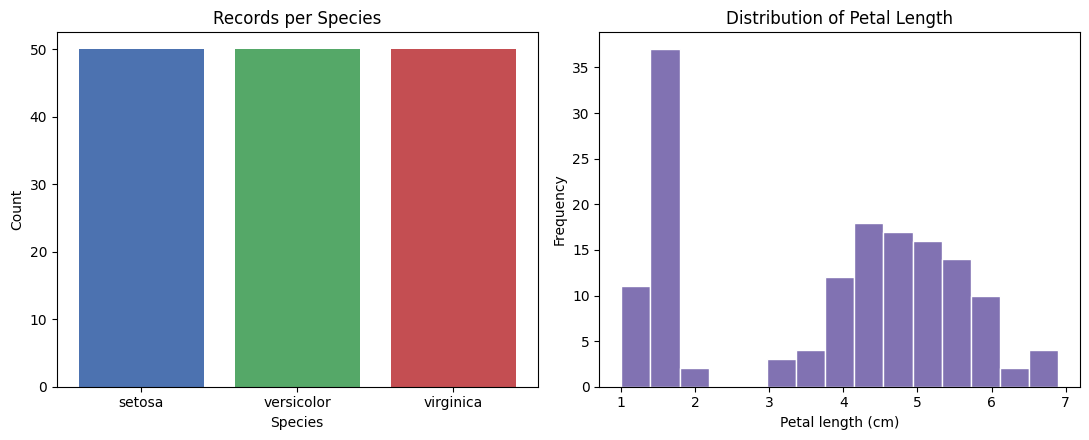

In [10]:
# ------------------------------------------------------------------
# Charts
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].bar(species_counts.index, species_counts.values,
            color=["#4C72B0", "#55A868", "#C44E52"][: len(species_counts)])
axes[0].set_title("Records per Species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Count")

axes[1].hist(df["petal_length"], bins=15, color="#8172B2", edgecolor="white")
axes[1].set_title("Distribution of Petal Length")
axes[1].set_xlabel("Petal length (cm)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("iris_charts.png", dpi=150)
plt.show()

In [11]:
# ------------------------------------------------------------------
# 3 Observations (computed from the data)
# ------------------------------------------------------------------
low_len = group_means["petal_length"].idxmin()
low_wid_sepal = group_means["sepal_width"].idxmax()
range_by_species = df.groupby("species")["petal_length"].agg(["min", "max"])
overlap_note = (
    "their petal-length ranges do not overlap"
    if (range_by_species["min"].sort_values().iloc[1:].values
        > range_by_species["max"].sort_values().iloc[:-1].values).all()
    else "some species' petal-length ranges overlap"
)

print("\n=== 3 Observations ===")
print(f"1. {top_len} has the largest average petal length "
      f"({group_means.loc[top_len, 'petal_length']} cm) and {top_wid} the widest petals "
      f"({group_means.loc[top_wid, 'petal_width']} cm); {low_len} has the smallest petals "
      f"({group_means.loc[low_len, 'petal_length']} cm).")
print(f"2. Petal length distinguishes species better than sepal width: {overlap_note}, "
      f"while {low_wid_sepal} has the widest sepals on average despite having the smallest petals.")
print(f"3. Data quality: {int(df.isnull().sum().sum())} missing values and {int(n_dupes)} "
      f"duplicate rows across {len(df)} records; classes are "
      f"{'balanced' if species_counts.nunique() == 1 else 'unbalanced'} "
      f"({', '.join(f'{k}: {v}' for k, v in species_counts.items())}).")


=== 3 Observations ===
1. virginica has the largest average petal length (5.552 cm) and virginica the widest petals (2.026 cm); setosa has the smallest petals (1.462 cm).
2. Petal length distinguishes species better than sepal width: some species' petal-length ranges overlap, while setosa has the widest sepals on average despite having the smallest petals.
3. Data quality: 0 missing values and 1 duplicate rows across 150 records; classes are balanced (setosa: 50, versicolor: 50, virginica: 50).


In [12]:
# ------------------------------------------------------------------
# 3 Observations (computed from the data)
# ------------------------------------------------------------------
low_len = group_means["petal_length"].idxmin()
low_wid_sepal = group_means["sepal_width"].idxmax()
range_by_species = df.groupby("species")["petal_length"].agg(["min", "max"])
overlap_note = (
    "their petal-length ranges do not overlap"
    if (range_by_species["min"].sort_values().iloc[1:].values
        > range_by_species["max"].sort_values().iloc[:-1].values).all()
    else "some species' petal-length ranges overlap"
)

print("\n=== 3 Observations ===")
print(f"1. {top_len} has the largest average petal length "
      f"({group_means.loc[top_len, 'petal_length']} cm) and {top_wid} the widest petals "
      f"({group_means.loc[top_wid, 'petal_width']} cm); {low_len} has the smallest petals "
      f"({group_means.loc[low_len, 'petal_length']} cm).")
print(f"2. Petal length distinguishes species better than sepal width: {overlap_note}, "
      f"while {low_wid_sepal} has the widest sepals on average despite having the smallest petals.")
print(f"3. Data quality: {int(df.isnull().sum().sum())} missing values and {int(n_dupes)} "
      f"duplicate rows across {len(df)} records; classes are "
      f"{'balanced' if species_counts.nunique() == 1 else 'unbalanced'} "
      f"({', '.join(f'{k}: {v}' for k, v in species_counts.items())}).")


=== 3 Observations ===
1. virginica has the largest average petal length (5.552 cm) and virginica the widest petals (2.026 cm); setosa has the smallest petals (1.462 cm).
2. Petal length distinguishes species better than sepal width: some species' petal-length ranges overlap, while setosa has the widest sepals on average despite having the smallest petals.
3. Data quality: 0 missing values and 1 duplicate rows across 150 records; classes are balanced (setosa: 50, versicolor: 50, virginica: 50).
